# What is image segmentation?

Image segmentation is about dividing the image into different sections each highlighting a certain object for example which could help us in identifying the contents of the image

# Segmentation techniques

**Image thresholding and how it works:**

(could be applied on binary or grayscale image converted to binary then)
1.   **Choose a threshold value**: select a pixel intensity value T ( could be based on what are you trying to detect so for example we are detecting a tumor so we could set the threshold to be the intensity value of the tumor pixels)
2.   **Segment the image**: for each pixel in the image:
    * if the pixel value is greater than T, classify it as a foreground (or one region)
    * if the pixel value is less than or equal to T classify it as a background (or another region)

----


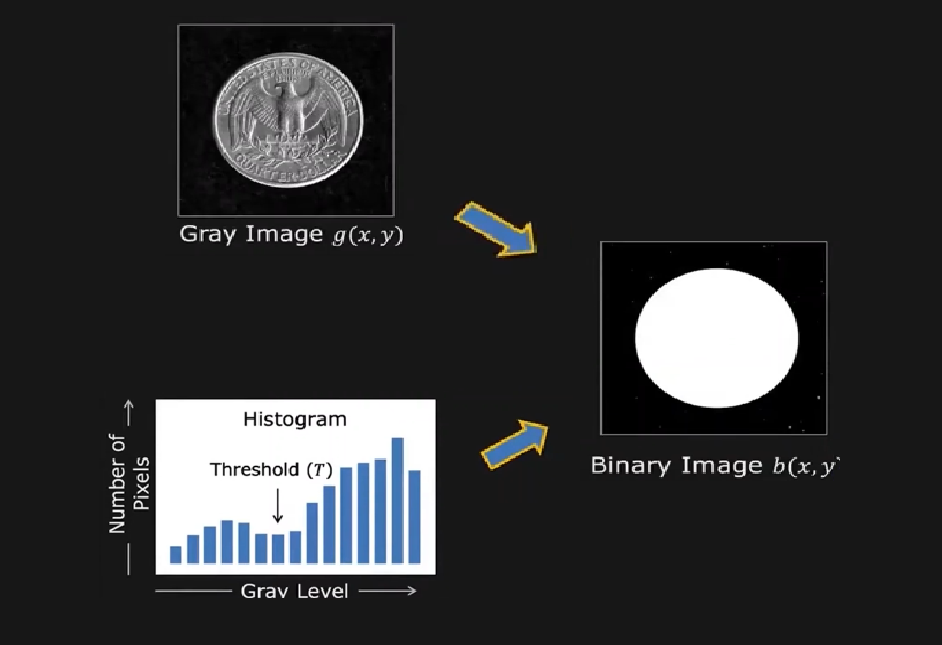

**K means**
The idea of k-means which is a clustering algorithm is that we want to group similar pixel values under a group by assuming that objects with the same characteristics will have similar pixel values. Now I am segmenting my image into regions
  * we initialize a number of clusters (regions). The we randomly select a centriod and a centriod is simply a value we assume it's going to be in the center of the cluster or group we have
  * The next step would be grouping the pixels closer to a centriod with it (by computing the distance) such that each pixel value will belong to a cluster. This step is repeated until convergence is reached
  * Each pixel belonging to a group will be colored with a color specific to this group to easily identify the regions in the image


# **K means Segmentation**

In [15]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [16]:
# read Image

image = cv2.imread('/content/road.jpg')

In [17]:
# shape

image.shape

(627, 1200, 3)

In [ ]:
# convert from BGR to RGB

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

In [18]:
#GaussianBlur

image = cv2.GaussianBlur(image, (3,3),0)

In [19]:
# we are reshapping the 3d array that represented the pixel values where we had rows and columns for showing the width and height along with
# the color intensity for each value.

# instead we flatten the image to be a 2d array where instead we will have rows only and each row will represent the color intensity for each pixel..
# like that for example

# Before reshapping --> (3*2 pixels ,3) image
# [
#   [[R1, G1, B1], [R2, G2, B2]],  # Row 1
#   [[R3, G3, B3], [R4, G4, B4]],  # Row 2
#   [[R5, G5, B5], [R6, G6, B6]]   # Row 3
# ]

# After reshapping --> (6 rows , 3)
# [
#   [R1, G1, B1],  # Pixel 1
#   [R2, G2, B2],  # Pixel 2
#   [R3, G3, B3],  # Pixel 3
#   [R4, G4, B4],  # Pixel 4
#   [R5, G5, B5],  # Pixel 5
#   [R6, G6, B6]   # Pixel 6
# ]

# This way, you can think of it as taking all the pixels and placing them side by side,
#creating a single "row" of pixel intensities, making it easier to process them in a linear fashion.

# 3D ---> 2D
# (627, 1200, 3) -----> (627 * 1200, 3)

pixel_values = image.reshape((-1,3))

In [20]:
# convert the pixel values to float to get a more accurate calculation of the distance in kmean

pixel_values = np.float32(pixel_values)

# pixel_values

In [21]:
# we could stop when the convergence rate becomes lower than 75% which means low changes in the centriod's position
# max iterations are 100, epsilon value(convergance) is 0.75

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER , 100 , 0.75)

In [22]:
# retvals are the distances between the pixel and the centriods the smaller the better
# 10 attempts to initialize the random centriods
k=3
retvals , labels ,centers = cv2.kmeans(pixel_values, k , None , criteria , 10, cv2.KMEANS_RANDOM_CENTERS)

In [23]:
# converting the centeral pixel values of the cluters from float to int
# to be able to correctly represent the color as rgb is from 0 to 255
centers = np.uint8(centers)
print(centers) # color of each centriod

[[ 59  60  65]
 [224 219 214]
 [107 108 115]]


In [24]:
print(labels) # the cluster that each pixel belongs to

[[1]
 [1]
 [1]
 ...
 [0]
 [0]
 [0]]


In [25]:
# we are going through each pixel in the labels array where each has a number
# based on the amount of clusters we have and then we are coloring
# each pixel based on the center it belongs to

segmented_data = centers[labels.flatten()] # want to match the color of the pixel based on the cluster it belongs to
segmented_data

array([[224, 219, 214],
       [224, 219, 214],
       [224, 219, 214],
       ...,
       [ 59,  60,  65],
       [ 59,  60,  65],
       [ 59,  60,  65]], dtype=uint8)

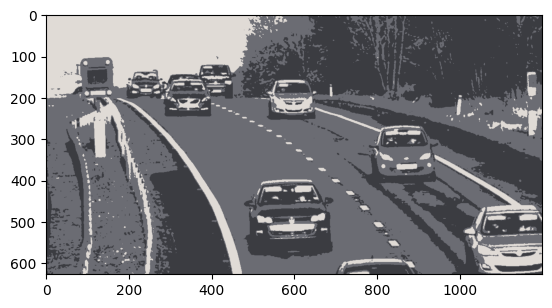

In [26]:
segmented_image = segmented_data.reshape(image.shape)
plt.imshow(segmented_image)

# Task solution: Segement an image captured from an airplane like a landscape or cities

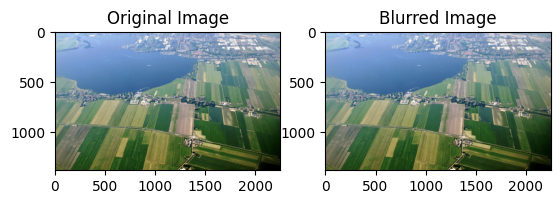

In [27]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read the image captured from airplane
image = cv2.imread('/content/airplane_landscape.png')

# Convert the image from BGR to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display the original image
plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title('Original Image')

# Remove noise using Gaussian blur
blurred_image = cv2.GaussianBlur(image, (5, 5), 0)

# Display the image after Gaussian blur
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(blurred_image, cv2.COLOR_BGR2RGB))
plt.title('Blurred Image')
plt.show()

# Flatten the image to a 2D array of pixels
pixels = blurred_image.reshape((-1, 3))

# Convert to float type
pixels = np.float32(pixels)




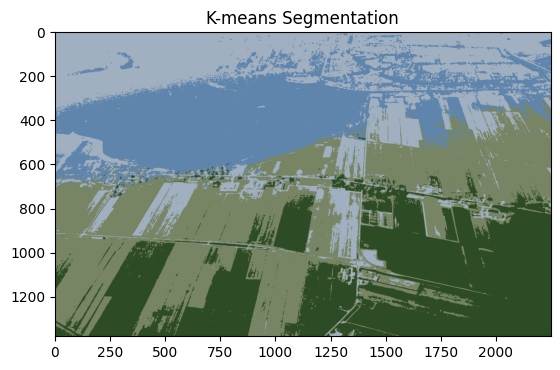

In [28]:
# Define criteria and apply kmeans()
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
k = 4  # Number of clusters (you can adjust this)
_, labels, centers = cv2.kmeans(pixels, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Convert back to 8-bit values
centers = np.uint8(centers)

# Map the labels to the centers
segmented_image = centers[labels.flatten()]

# Reshape back to the original image shape
segmented_image = segmented_image.reshape(image.shape)

# Display the segmented image
plt.imshow(cv2.cvtColor(segmented_image, cv2.COLOR_BGR2RGB))
plt.title('K-means Segmentation')
plt.show()